In [11]:
# import libraries
import re
import urllib.request
import requests
from bs4 import BeautifulSoup
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# set up sentiment analysis
import nltk
nltk.download('vader_lexicon')
from nltk.sentiment import SentimentIntensityAnalyzer

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/sebastian/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [14]:
# load image
image_path = "medmnist_xray_grid.png"
img = Image.open(image_path)
img_array = np.array(img)

print(f"Original grid shape: {img_array.shape}")

# split image
n_rows = 10
n_cols = 10
h = img_array.shape[0] // n_rows
w = img_array.shape[1] // n_cols

Original grid shape: (1120, 1120)


Split array shape: (100, 112, 112)
Total individual X-rays extracted: 100


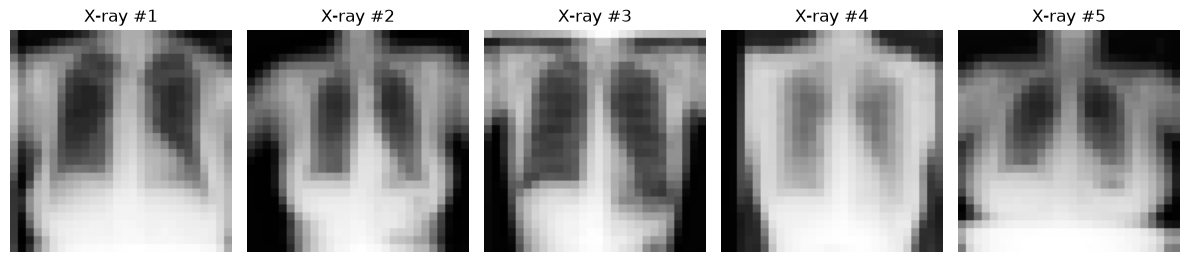

In [15]:
# individual xrays
xrays = []
for r in range(n_rows):
    for c in range(n_cols):
        patch = img_array[r * h : (r + 1) * h, c * w : (c + 1) * w]
        xrays.append(patch)

# convert to numpy array
xrays = np.array(xrays)

print(f"Split array shape: {xrays.shape}")
print(f"Total individual X-rays extracted: {len(xrays)}")

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i in range(5):
    axes[i].imshow(xrays[i], cmap='gray' if xrays.ndim == 3 else None)
    axes[i].set_title(f"X-ray #{i+1}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()